In [1]:
# ============================================================
# PHASE 5: EVALUATION
# Compares all three ACRS layers and produces the thesis figures
# ============================================================

import numpy as np
import pandas as pd
import pickle, json, warnings
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
warnings.filterwarnings('ignore')

# Load data
X_train = pd.read_parquet('acrs_data/X_train.parquet')
X_test  = pd.read_parquet('acrs_data/X_test.parquet')
y_test  = np.load('acrs_data/y_test.npy')

# Load models
with open('acrs_data/xgb_final.pkl','rb')  as f: xgb_final  = pickle.load(f)
with open('acrs_data/lgbm_final.pkl','rb') as f: lgbm_final = pickle.load(f)
with open('acrs_data/rf_final.pkl','rb')   as f: rf_final   = pickle.load(f)

# Load saved results
with open('acrs_data/layer2_results.json') as f: l2 = json.load(f)
with open('acrs_data/layer3_results.json') as f: l3 = json.load(f)

# Recompute all predictions
prob_xgb  = xgb_final.predict_proba(X_test)[:,1]
prob_lgbm = lgbm_final.predict_proba(X_test)[:,1]
prob_rf   = rf_final.predict_proba(X_test)[:,1]
prob_ens  = (prob_xgb + prob_lgbm + prob_rf) / 3

print(f"Loaded! | X_test: {X_test.shape}")
print(f"Predictions ready: XGBoost, LightGBM, RF, Ensemble")

Loaded! | X_test: (504194, 83)
Predictions ready: XGBoost, LightGBM, RF, Ensemble


In [3]:
# ============================================================
# EVALUATION CELL 2: 3-Layer Comparison + Wilcoxon Test
#
# Wilcoxon signed-rank test answers: "Is the difference between
# two models statistically significant, or just random chance?"
# We compare each individual model vs the ensemble.
# p < 0.05 = the difference is real, not luck.
# ============================================================

from sklearn.metrics import roc_auc_score, f1_score
from scipy.stats import wilcoxon, ks_2samp

def get_metrics(y_true, y_prob):
    auc  = roc_auc_score(y_true, y_prob)
    ks   = ks_2samp(y_prob[y_true==1], y_prob[y_true==0]).statistic
    gini = 2 * auc - 1
    f1   = f1_score(y_true, (y_prob >= 0.5).astype(int))
    return auc, ks, gini, f1

# ── Individual model metrics ─────────────────────────────────
auc_xgb,  ks_xgb,  gini_xgb,  f1_xgb  = get_metrics(y_test, prob_xgb)
auc_lgbm, ks_lgbm, gini_lgbm, f1_lgbm = get_metrics(y_test, prob_lgbm)
auc_rf,   ks_rf,   gini_rf,   f1_rf   = get_metrics(y_test, prob_rf)
auc_ens,  ks_ens,  gini_ens,  f1_ens  = get_metrics(y_test, prob_ens)

# ── Wilcoxon test: individual vs ensemble ────────────────────
# We compare per-sample absolute errors (|prob - true_label|)
# Lower error = better. We test if ensemble error is significantly lower.
err_xgb  = np.abs(prob_xgb  - y_test)
err_lgbm = np.abs(prob_lgbm - y_test)
err_rf   = np.abs(prob_rf   - y_test)
err_ens  = np.abs(prob_ens  - y_test)

# Sample 10k for Wilcoxon (full 500k causes memory issue)
np.random.seed(42)
idx = np.random.choice(len(y_test), 10000, replace=False)

_, p_xgb  = wilcoxon(err_xgb[idx],  err_ens[idx])
_, p_lgbm = wilcoxon(err_lgbm[idx], err_ens[idx])
_, p_rf   = wilcoxon(err_rf[idx],   err_ens[idx])

def sig(p): return "***" if p < 0.001 else ("**" if p < 0.01 else ("*" if p < 0.05 else "ns"))

# ── Print comparison table ───────────────────────────────────
print("=" * 72)
print(f"{'Model':<18} {'AUC':>7} {'KS':>7} {'Gini':>7} {'F1':>7}  {'Wilcoxon p':>12}  Sig")
print("=" * 72)
print(f"{'XGBoost':<18} {auc_xgb:>7.4f} {ks_xgb:>7.4f} {gini_xgb:>7.4f} {f1_xgb:>7.4f}  {p_xgb:>12.4e}  {sig(p_xgb)}")
print(f"{'LightGBM':<18} {auc_lgbm:>7.4f} {ks_lgbm:>7.4f} {gini_lgbm:>7.4f} {f1_lgbm:>7.4f}  {p_lgbm:>12.4e}  {sig(p_lgbm)}")
print(f"{'RandomForest':<18} {auc_rf:>7.4f} {ks_rf:>7.4f} {gini_rf:>7.4f} {f1_rf:>7.4f}  {p_rf:>12.4e}  {sig(p_rf)}")
print(f"{'Ensemble (L1-3)':<18} {auc_ens:>7.4f} {ks_ens:>7.4f} {gini_ens:>7.4f} {f1_ens:>7.4f}  {'(baseline)':>12}  —")
print("=" * 72)
print("Sig: *** p<0.001  ** p<0.01  * p<0.05  ns = not significant")

# ── 3-Layer ACRS comparison ──────────────────────────────────
print("\n" + "=" * 65)
print(f"{'Capability':<30} {'Layer 1':>10} {'Layer 2':>10} {'Layer 3':>10}")
print("=" * 65)
print(f"{'AUC-ROC':<30} {auc_ens:>10.4f} {l2['auc']:>10.4f} {l3['auc']:>10.4f}")
print(f"{'KS Statistic':<30} {ks_ens:>10.4f} {l2['ks']:>10.4f} {l3['ks']:>10.4f}")
print(f"{'Gini Coefficient':<30} {gini_ens:>10.4f} {l2['gini']:>10.4f} {l3['gini']:>10.4f}")
print(f"{'F1 Score':<30} {f1_ens:>10.4f} {l2['f1']:>10.4f} {l3['f1']:>10.4f}")
print(f"{'PSI Monitoring':<30} {'✗':>10} {'0.0176':>10} {'0.0176':>10}")
print(f"{'Drift Detection':<30} {'✗':>10} {'✗':>10} {'10 alerts':>10}")
print(f"{'Real-time SHAP':<30} {'✗':>10} {'Batch':>10} {'Per-loan':>10}")
print(f"{'HITL Trigger':<30} {'✗':>10} {'✗':>10} {'1.0%':>10}")
print(f"{'Audit Trail':<30} {'✗':>10} {'✗':>10} {'✓':>10}")
print("=" * 65)

Model                  AUC      KS    Gini      F1    Wilcoxon p  Sig
XGBoost             0.7438  0.3448  0.4876  0.2401   2.0821e-177  ***
LightGBM            0.7409  0.3413  0.4818  0.2330   4.8678e-226  ***
RandomForest        0.7374  0.3342  0.4747  0.2052   3.0520e-248  ***
Ensemble (L1-3)     0.7424  0.3433  0.4848  0.2189    (baseline)  —
Sig: *** p<0.001  ** p<0.01  * p<0.05  ns = not significant

Capability                        Layer 1    Layer 2    Layer 3
AUC-ROC                            0.7424     0.7424     0.7424
KS Statistic                       0.3433     0.3433     0.3433
Gini Coefficient                   0.4848     0.4848     0.4848
F1 Score                           0.2189     0.2189     0.2189
PSI Monitoring                          ✗     0.0176     0.0176
Drift Detection                         ✗          ✗  10 alerts
Real-time SHAP                          ✗      Batch   Per-loan
HITL Trigger                            ✗          ✗       1.0%
Audit Trail    

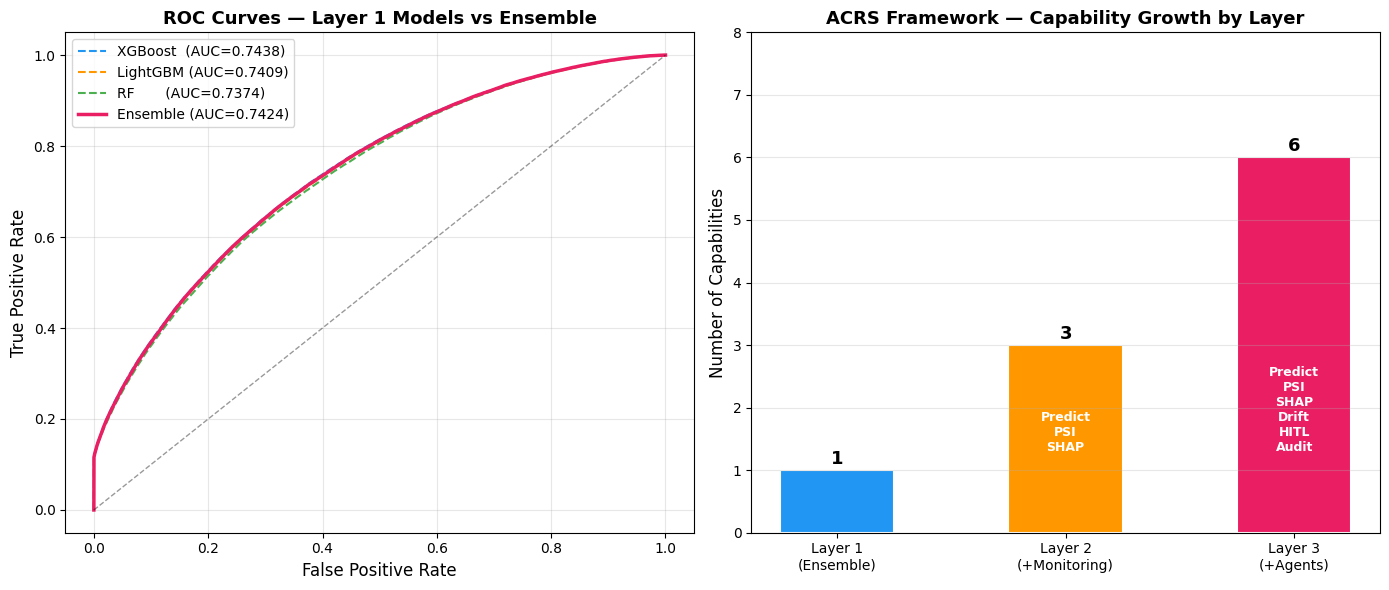

Saved: fig_roc_capability.png


In [5]:
# ── FIGURE 1: ROC Curves ─────────────────────────────────────
from sklearn.metrics import roc_curve

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Left: ROC curves for all models
ax = axes[0]
for prob, label, color, auc in [
    (prob_xgb,  f'XGBoost  (AUC={auc_xgb:.4f})',  '#2196F3', auc_xgb),
    (prob_lgbm, f'LightGBM (AUC={auc_lgbm:.4f})', '#FF9800', auc_lgbm),
    (prob_rf,   f'RF       (AUC={auc_rf:.4f})',    '#4CAF50', auc_rf),
    (prob_ens,  f'Ensemble (AUC={auc_ens:.4f})',   '#E91E63', auc_ens),
]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    lw = 2.5 if 'Ensemble' in label else 1.5
    ax.plot(fpr, tpr, label=label, linewidth=lw,
            linestyle='-' if 'Ensemble' in label else '--', color=color)

ax.plot([0,1],[0,1],'k--', alpha=0.4, linewidth=1)
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('ROC Curves — Layer 1 Models vs Ensemble', fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(alpha=0.3)

# Right: 3-Layer capability radar / bar comparison
ax2 = axes[1]
layers = ['Layer 1\n(Ensemble)', 'Layer 2\n(+Monitoring)', 'Layer 3\n(+Agents)']
capabilities = [1, 3, 6]   # number of capabilities: L1=1, L2=3, L3=6
colors = ['#2196F3', '#FF9800', '#E91E63']
bars = ax2.bar(layers, capabilities, color=colors, width=0.5, edgecolor='white', linewidth=1.5)
ax2.set_ylabel('Number of Capabilities', fontsize=12)
ax2.set_title('ACRS Framework — Capability Growth by Layer', fontsize=13, fontweight='bold')
ax2.set_ylim(0, 8)
for bar, cap in zip(bars, capabilities):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
             str(cap), ha='center', fontsize=13, fontweight='bold')

# Annotate what each layer adds
ax2.text(0, 1.3, 'Predict', ha='center', fontsize=9, color='white', fontweight='bold')
ax2.text(1, 1.3, 'Predict\nPSI\nSHAP', ha='center', fontsize=9, color='white', fontweight='bold')
ax2.text(2, 1.3, 'Predict\nPSI\nSHAP\nDrift\nHITL\nAudit', ha='center',
         fontsize=9, color='white', fontweight='bold')
ax2.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('acrs_data/fig_roc_capability.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: fig_roc_capability.png")

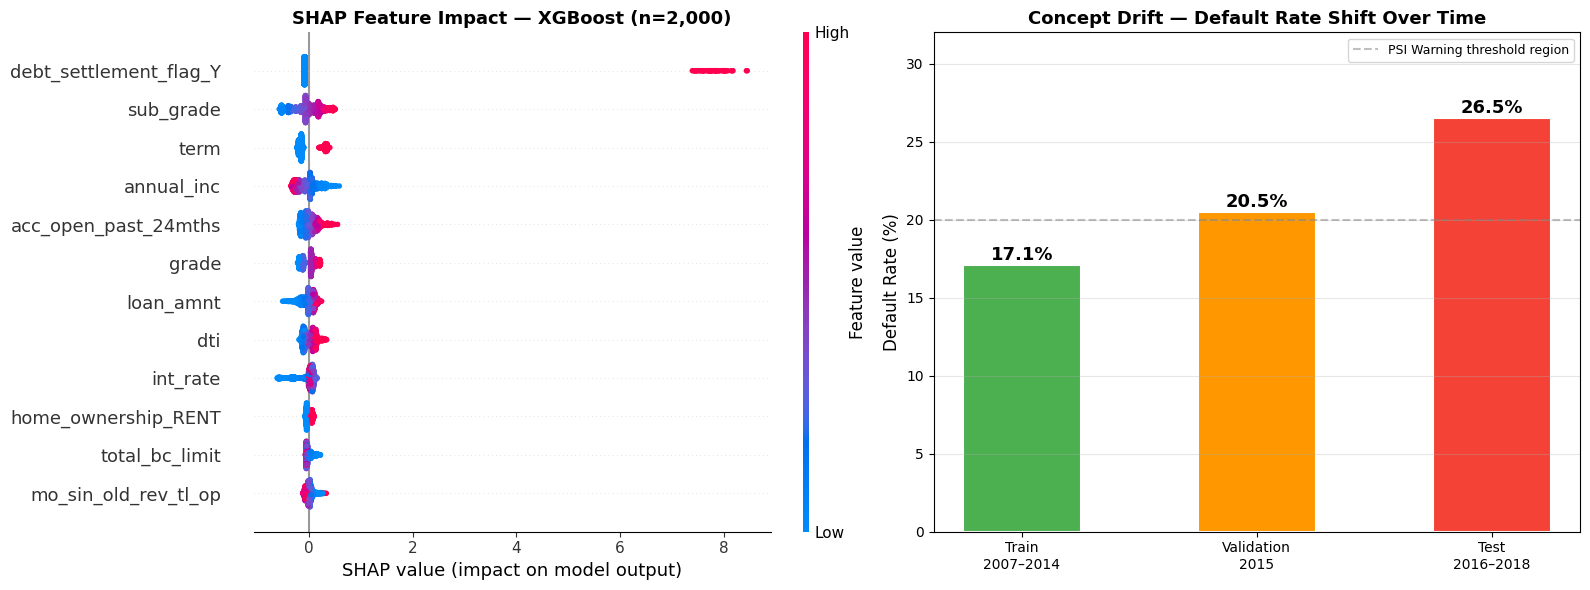

Saved: fig_shap_drift.png


In [7]:
# ── FIGURE 2: SHAP Beeswarm + Drift Timeline ─────────────────
import shap

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: SHAP beeswarm (load saved values from Layer 2)
shap_vals = np.load('acrs_data/shap_values_xgb_sample.npy')
X_sample  = X_test.iloc[np.random.RandomState(42).choice(len(X_test), 2000, replace=False)]

plt.sca(axes[0])
shap.summary_plot(shap_vals, X_sample, max_display=12, show=False, plot_size=None)
axes[0].set_title('SHAP Feature Impact — XGBoost (n=2,000)', fontsize=13, fontweight='bold')

# Right: Drift timeline — default rate across time buckets
# Shows the natural concept drift: 17% → 20% → 26%
ax3 = axes[1]
periods  = ['Train\n2007–2014', 'Validation\n2015', 'Test\n2016–2018']
def_rates = [17.1, 20.5, 26.5]
colors3  = ['#4CAF50', '#FF9800', '#F44336']
bars3 = ax3.bar(periods, def_rates, color=colors3, width=0.5, edgecolor='white', linewidth=1.5)
ax3.set_ylabel('Default Rate (%)', fontsize=12)
ax3.set_title('Concept Drift — Default Rate Shift Over Time', fontsize=13, fontweight='bold')
ax3.set_ylim(0, 32)
for bar, rate in zip(bars3, def_rates):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
             f'{rate}%', ha='center', fontsize=13, fontweight='bold')
ax3.axhline(y=20, color='gray', linestyle='--', alpha=0.5, label='PSI Warning threshold region')
ax3.grid(axis='y', alpha=0.3)
ax3.legend(fontsize=9)

plt.tight_layout()
plt.savefig('acrs_data/fig_shap_drift.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: fig_shap_drift.png")